## Scouting Geométrico ⚽📐

Ustedes son los Ingeniros de Datos del departamento de Scouting de un equipo de élite. Estamos a mitad de la temporada 2025-2026 y nuestro jugador estrella acaba de sufrir una lesión grave. El director técnico necesita un reemplazo urgente. No tiene tiempo para ver cientos de videos; quiere que encuentren al jugador "matemáticamente más idéntico" en toda la liga.

Para la computadora, los jugadores de fútbol no son personas; son vectores flotando en un espacio multidimensional. Su misión es construir este espacio utilizando el archivo players_data-2025_2026.csv y encontrar al clon exacto de nuestra estrella.

### Fase 1: Construyendo el Multiverso del Jugador (Min. 4 Dimensiones)
Creen un Jupyter Notebook nuevo, carguen el dataset proporcionado en GitHub y seleccionen a su "Jugador Estrella" (puede ser el jugador con más goles o su favorito del dataset, la decisión es suya).

**Misión:**

Construyan la matriz multidimensional X seleccionando al menos 4 características numéricas (pueden ser más) continuas (float) que definan el rendimiento del jugador (por ejemplo: Goles, Asistencias, Minutos_Jugados, Precisión_Pases, Recuperaciones, etc.).
Creen un vector para su jugador estrella y otro vector para el resto de los candidatos.
Pregunta de control: Antes de medir cualquier distancia, ¿qué operación de la Unidad II deben aplicarle obligatoriamente a estas 4 columnas para que los Minutos_Jugados (rango en miles) no aplasten matemáticamente a los Goles (rango en decenas)? Apliquen esa transformación en el código.


In [4]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

url = "../players-data.csv"
df = pd.read_csv(url)

In [5]:
df.describe()

,Rk,Age,Born,MP,Starts,Min,90s,Gls,Ast,G+A,...,CrdY_stats_misc,CrdR_stats_misc,2CrdY,Fls,Fld,Off,Crs,Int,TklW,OG
count,2839.000000,2837.000000,2837.000000,2839.000000,2839.000000,2839.000000,2839.000000,2839.000000,2839.000000,2839.000000,...,2839.000000,2839.000000,2839.000000,2839.000000,2839.000000,2839.000000,2839.000000,2839.000000,2839.000000,2839.000000
mean,1420.000000,24.855834,1999.802256,19.138781,13.576611,1218.580134,13.539803,1.660444,1.159211,2.819655,...,2.412821,0.121169,0.041564,14.497710,13.752730,2.060937,21.657978,10.141951,11.924974,0.045791
std,819.693032,4.623789,4.633160,11.520385,11.225366,963.218994,10.703241,2.932688,1.833065,4.134442,...,2.526406,0.352339,0.204853,13.493894,14.665142,3.801657,34.963118,11.810994,12.430342,0.228399
min,1.000000,15.000000,1983.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,710.500000,21.000000,1997.000000,9.000000,3.000000,320.500000,3.600000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,1.000000,1.000000,1.000000,0.000000
50%,1420.000000,25.000000,2000.000000,20.000000,12.000000,1074.000000,11.900000,0.000000,0.000000,1.000000,...,2.000000,0.000000,0.000000,12.000000,9.000000,1.000000,6.000000,5.000000,8.000000,0.000000
75%,2129.500000,28.000000,2003.000000,29.000000,23.000000,1972.500000,21.900000,2.000000,2.000000,4.000000,...,4.000000,0.000000,0.000000,23.000000,20.000000,2.500000,26.500000,16.000000,19.000000,0.000000
max,2839.000000,41.000000,2010.000000,38.000000,38.000000,3420.000000,38.000000,36.000000,21.000000,41.000000,...,13.000000,3.000000,2.000000,87.000000,118.000000,41.000000,295.000000,77.000000,72.000000,2.000000


In [6]:
features = ['Gls', 'Ast', 'Min', 'SoT']

scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[features] = scaler.fit_transform(df[features])

nombre_estrella = 'Robert Lewandowski'
vector_estrella = df_scaled[df_scaled['Player'] == nombre_estrella][features].values[0]

candidatos = df_scaled[df_scaled['Player'] != nombre_estrella].copy()

candidato_manhattan = {"name":"", "distance":""}
candidato_euclidiana = {"name":"", "distance":""}

for row in candidatos.itertuples():
    vector_candidato = np.array([getattr(row, feature) for feature in features])

    distancia_manhattan = np.sum(np.abs(vector_candidato - vector_estrella))
    distancia_euclidiana = np.sqrt(np.sum((vector_candidato - vector_estrella) ** 2))

    if candidato_manhattan['distance'] == "" or distancia_manhattan < candidato_manhattan['distance']:
        candidato_manhattan['name'] = row.Player
        candidato_manhattan['distance'] = distancia_manhattan

    if candidato_euclidiana['distance'] == "" or distancia_euclidiana < candidato_euclidiana['distance']:
        candidato_euclidiana['name'] = row.Player
        candidato_euclidiana['distance'] = distancia_euclidiana

print(f"Vector de {nombre_estrella} estandarizado: \n{vector_estrella}")
print(f"Jugador más similar a {nombre_estrella} según distancia Manhattan: {candidato_manhattan['name']} con distancia {candidato_manhattan['distance']}")
print(f"Jugador más similar a {nombre_estrella} según distancia Euclidiana: {candidato_euclidiana['name']} con distancia {candidato_euclidiana['distance']}")

Vector de Robert Lewandowski estandarizado: 
[4.20833396 0.45876024 0.46250991 3.13420975]
Jugador más similar a Robert Lewandowski según distancia Manhattan: Donyell Malen con distancia 0.469282159047875
Jugador más similar a Robert Lewandowski según distancia Euclidiana: Donyell Malen con distancia 0.3345486311492111


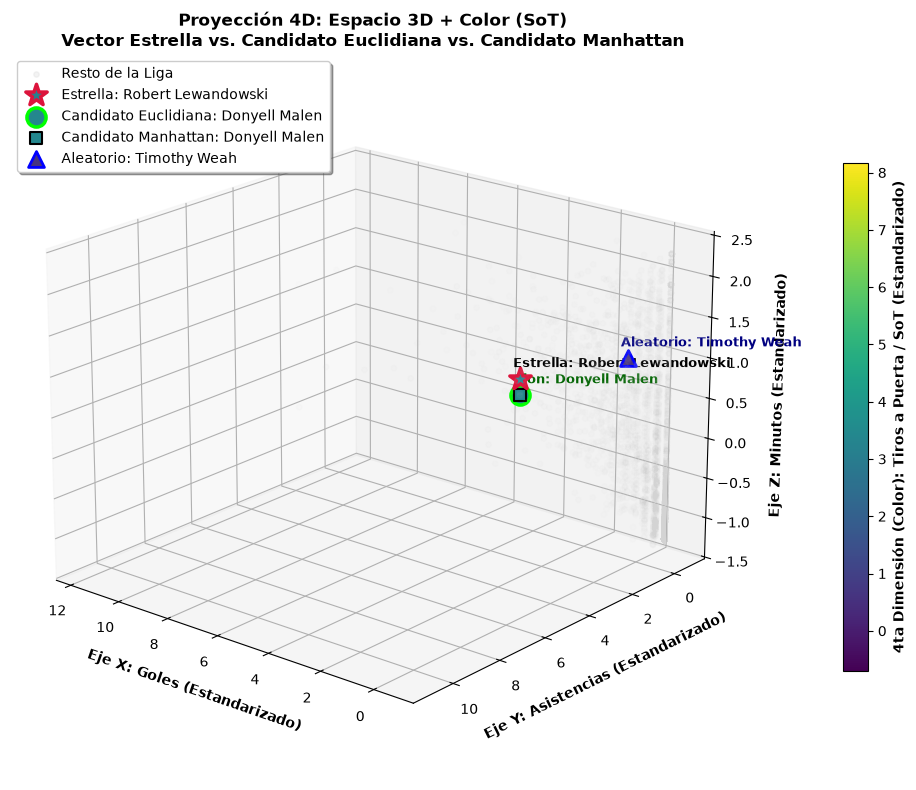

In [7]:
# Grafico AI assited, queria que se viera mas bonito

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# 1. Vectores y cálculo de distancias directo para asegurar que existan las columnas
vector_estrella = (
    df_scaled[df_scaled['Player'] == nombre_estrella][features]
    .values[0]
    .astype(float)
)
matriz_candidatos = candidatos[features].values.astype(float)

# Calculamos las distancias en candidatos para evitar el KeyError
candidatos['dist_euclidiana'] = np.linalg.norm(
    matriz_candidatos - vector_estrella, axis=1
)
candidatos['dist_manhattan'] = np.sum(
    np.abs(matriz_candidatos - vector_estrella), axis=1
)

# Obtenemos los candidatos con distancia mínima
top_euc = candidatos.sort_values('dist_euclidiana').iloc[0]
top_man = candidatos.sort_values('dist_manhattan').iloc[0]

vector_candidato_euclidiana = top_euc[features].values.astype(float)
vector_candidato_manhattan = top_man[features].values.astype(float)

# Jugador aleatorio para cumplir con el contraste que pide la Fase 3
random_row = candidatos[candidatos['Player'] != top_euc['Player']].sample(
    1, random_state=43
).iloc[0]
vector_aleatorio = random_row[features].values.astype(float)

# 2. Configurar la figura 3D
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')

# Fondo: Todos los jugadores de la liga para dar perspectiva del espacio
ax.scatter(
    df_scaled['Gls'],
    df_scaled['Ast'],
    df_scaled['Min'],
    c='lightgray',
    alpha=0.25,
    s=15,
    label='Resto de la Liga',
)

# Escala unificada de color para la 4ta dimensión (SoT)
vmin, vmax = df_scaled['SoT'].min(), df_scaled['SoT'].max()

# 3. Vector Estrella (Robert Lewandowski) -> Estrella grande con borde rojo
sc_estrella = ax.scatter(
    vector_estrella[0],
    vector_estrella[1],
    vector_estrella[2],
    c=vector_estrella[3],
    cmap='viridis',
    vmin=vmin,
    vmax=vmax,
    s=260,
    marker='*',
    edgecolors='crimson',
    linewidths=2.5,
    label=f'Estrella: {nombre_estrella}',
)
ax.text(
    vector_estrella[0] + 0.15,
    vector_estrella[1] + 0.15,
    vector_estrella[2] + 0.15,
    f'Estrella: {nombre_estrella}',
    weight='bold',
    fontsize=9,
)

# 4. Vector Candidato Euclidiana (Donyell Malen) -> Círculo grande con borde verde
sc_euc = ax.scatter(
    vector_candidato_euclidiana[0],
    vector_candidato_euclidiana[1],
    vector_candidato_euclidiana[2],
    c=vector_candidato_euclidiana[3],
    cmap='viridis',
    vmin=vmin,
    vmax=vmax,
    s=190,
    marker='o',
    edgecolors='lime',
    linewidths=2.5,
    label=f'Candidato Euclidiana: {top_euc["Player"]}',
)

# 5. Vector Candidato Manhattan (Donyell Malen) -> Cuadrado concéntrico interior con borde negro
# Como ambos algoritmos eligieron al mismo jugador, el cuadrado dentro del círculo evita que se tapen
sc_man = ax.scatter(
    vector_candidato_manhattan[0],
    vector_candidato_manhattan[1],
    vector_candidato_manhattan[2],
    c=vector_candidato_manhattan[3],
    cmap='viridis',
    vmin=vmin,
    vmax=vmax,
    s=85,
    marker='s',
    edgecolors='black',
    linewidths=1.5,
    label=f'Candidato Manhattan: {top_man["Player"]}',
)
ax.text(
    vector_candidato_manhattan[0] + 0.15,
    vector_candidato_manhattan[1] + 0.15,
    vector_candidato_manhattan[2] + 0.15,
    f'Clon: {top_man["Player"]}',
    weight='bold',
    fontsize=9,
    color='darkgreen',
)

# 6. Vector Jugador Aleatorio (contraste visual de Fase 3)
sc_rnd = ax.scatter(
    vector_aleatorio[0],
    vector_aleatorio[1],
    vector_aleatorio[2],
    c=vector_aleatorio[3],
    cmap='viridis',
    vmin=vmin,
    vmax=vmax,
    s=130,
    marker='^',
    edgecolors='blue',
    linewidths=2,
    label=f'Aleatorio: {random_row["Player"]}',
)
ax.text(
    vector_aleatorio[0] + 0.15,
    vector_aleatorio[1] + 0.15,
    vector_aleatorio[2] + 0.15,
    f'Aleatorio: {random_row["Player"]}',
    weight='bold',
    fontsize=9,
    color='navy',
)

# 7. Etiquetas de ejes y barra de color
ax.set_xlabel('Eje X: Goles (Estandarizado)', weight='bold', labelpad=8)
ax.set_ylabel('Eje Y: Asistencias (Estandarizado)', weight='bold', labelpad=8)
ax.set_zlabel('Eje Z: Minutos (Estandarizado)', weight='bold', labelpad=8)

cbar = fig.colorbar(sc_estrella, ax=ax, pad=0.10, shrink=0.7)
cbar.set_label(
    '4ta Dimensión (Color): Tiros a Puerta / SoT (Estandarizado)', weight='bold'
)

plt.title(
    'Proyección 4D: Espacio 3D + Color (SoT)\nVector Estrella vs. Candidato'
    ' Euclidiana vs. Candidato Manhattan',
    weight='bold',
    fontsize=12,
)
ax.legend(loc='upper left', frameon=True, shadow=True)
ax.view_init(elev=20, azim=130)
plt.tight_layout()
plt.show()